In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    roc_curve, auc
)
from sklearn.preprocessing import label_binarize

In [3]:
sns.set(style="whitegrid")
RANDOM_STATE = 45

In [4]:
df = pd.read_csv('dirty_cafe_sales_processed.csv')
print(df.shape)
df.head()

(10000, 15)


,Transaction ID,Quantity,Price Per Unit,Total Spent,Transaction Date,Item_Coffee,Item_Cookie,Item_Juice,Item_Salad,Item_Sandwich,Item_Smoothie,Item_Tea,Payment Method_Credit Card,Payment Method_Digital Wallet,Location_Takeaway
0,TXN_1961373,0.25,0.25,0.125000,2023-09-08,True,False,False,False,False,False,False,True,False,True
1,TXN_4977031,0.75,0.50,0.458333,2023-05-16,False,False,False,False,False,False,False,False,False,False
2,TXN_4271903,0.75,0.00,0.291667,2023-07-19,False,True,False,False,False,False,False,True,False,False
3,TXN_7034554,0.25,1.00,0.375000,2023-04-27,False,False,False,True,False,False,False,False,True,True
4,TXN_3160411,0.25,0.25,0.125000,2023-06-11,True,False,False,False,False,False,False,False,True,False


In [5]:
df_model = df.drop(columns=['Transaction ID']).copy()
print(df_model.shape)
print(df_model.columns.tolist())

(10000, 14)
['Quantity', 'Price Per Unit', 'Total Spent', 'Transaction Date', 'Item_Coffee', 'Item_Cookie', 'Item_Juice', 'Item_Salad', 'Item_Sandwich', 'Item_Smoothie', 'Item_Tea', 'Payment Method_Credit Card', 'Payment Method_Digital Wallet', 'Location_Takeaway']


In [6]:
item_cols = [c for c in df_model.columns if c.startswith('Item_')]
print(item_cols)

['Item_Coffee', 'Item_Cookie', 'Item_Juice', 'Item_Salad', 'Item_Sandwich', 'Item_Smoothie', 'Item_Tea']


In [7]:
df_model['Item_Label'] = df_model[item_cols].idxmax(axis=1).str.replace('Item_', '')
print(df_model['Item_Label'].value_counts())

Item_Label
Coffee      2304
Juice       2140
Salad       1148
Sandwich    1131
Smoothie    1096
Cookie      1092
Tea         1089
Name: count, dtype: int64


In [8]:
TARGET_CLF = 'Item_Label'
X_clf = df_model.drop(columns=[TARGET_CLF, 'Transaction Date', 'Total Spent'] + item_cols)
y_clf = df_model[TARGET_CLF]

In [9]:
print(X_clf.shape)
print(X_clf.columns.tolist())
print(sorted(y_clf.unique()))

(10000, 5)
['Quantity', 'Price Per Unit', 'Payment Method_Credit Card', 'Payment Method_Digital Wallet', 'Location_Takeaway']
['Coffee', 'Cookie', 'Juice', 'Salad', 'Sandwich', 'Smoothie', 'Tea']


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2,
    random_state=RANDOM_STATE, stratify=y_clf
)

In [11]:
print(X_train.shape)
print(X_test.shape)

(8000, 5)
(2000, 5)


In [12]:
rf = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf.fit(X_train, y_train)

,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(y_true, y_pred)` to use acustom metric. Only available if `bootstrap=True`.For an illustration of out-of-bag (OOB) error estimation, see the example:ref:`sphx_glr_auto_examples_ensemble_plot_ensemble_oob.py`.",True
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",45
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.

In [15]:
print(rf.oob_score_)
print(1 - rf.oob_score_)

0.670875
0.329125


In [16]:
y_pred_rf = rf.predict(X_test)
print(accuracy_score(y_test, y_pred_rf))
print(classification_report(y_test, y_pred_rf, zero_division=0))

0.6885
              precision    recall  f1-score   support

      Coffee       0.70      0.66      0.68       461
      Cookie       0.89      0.94      0.92       218
       Juice       0.51      0.50      0.50       428
       Salad       0.88      0.93      0.90       230
    Sandwich       0.53      0.59      0.56       226
    Smoothie       0.50      0.47      0.49       219
         Tea       0.93      0.94      0.94       218

    accuracy                           0.69      2000
   macro avg       0.71      0.72      0.71      2000
weighted avg       0.69      0.69      0.69      2000



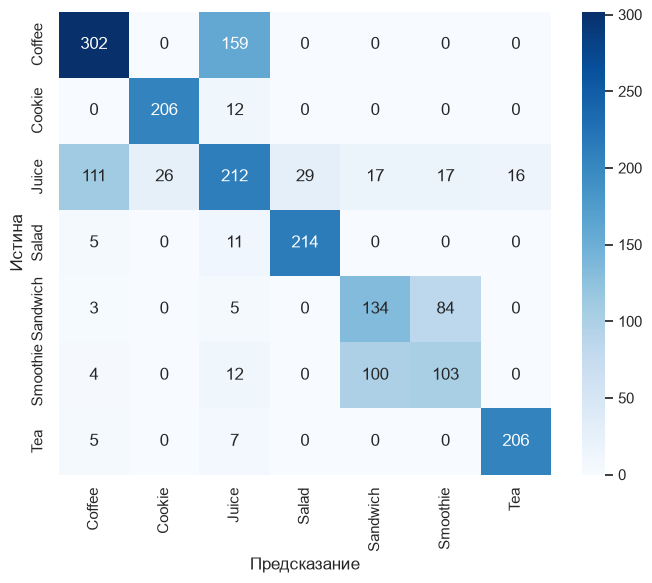

In [17]:
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=rf.classes_)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=rf.classes_,
            yticklabels=rf.classes_)
plt.ylabel('Истина')
plt.xlabel('Предсказание')
plt.tight_layout()
plt.show()

In [18]:
n_list = [10, 25, 50, 100, 200, 300]
oob_scores = []

for n in n_list:
    model = RandomForestClassifier(
        n_estimators=n, oob_score=True,
        random_state=RANDOM_STATE, n_jobs=-1
    )
    model.fit(X_train, y_train)
    oob_scores.append(model.oob_score_)

C:\Users\User\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\ensemble\_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


In [19]:
for n, s in zip(n_list, oob_scores):
    print(n, round(s, 4))

10 0.667
25 0.6703
50 0.669
100 0.6709
200 0.6689
300 0.6683


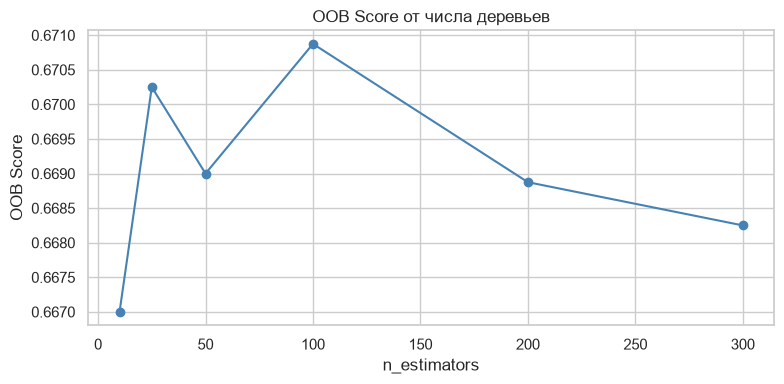

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(n_list, oob_scores, marker='o', color='steelblue')
plt.xlabel('n_estimators')
plt.ylabel('OOB Score')
plt.title('OOB Score от числа деревьев')
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
ada = AdaBoostClassifier(
    estimator=DecisionTreeClassifier(max_depth=1),
    n_estimators=100,
    random_state=RANDOM_STATE
)
ada.fit(X_train, y_train)

,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeC...r(max_depth=1)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",100
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",45
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",1.0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[object](7,)","['Coffee','Cookie','Juice',...,'Sandwich','Smoothie','Tea']"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](100,)","[0.66,0.6 ,0.6 ,...,0.83,0.84,0.83]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](100,)","[1.12,1.37,1.38,...,0.18,0.16,0.2 ]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=2100288459), DecisionTreeC...te=1307974046), DecisionTreeC...ate=212792963), DecisionTreeC...ate=736499580), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](5,)","[0.01,0.99,0. ,0. ,0. ]"


In [22]:
y_pred_ada = ada.predict(X_test)
print(accuracy_score(y_test, y_pred_ada))
print(classification_report(y_test, y_pred_ada, zero_division=0))

0.6815
              precision    recall  f1-score   support

      Coffee       0.89      0.51      0.65       461
      Cookie       0.89      0.94      0.92       218
       Juice       0.51      0.69      0.58       428
       Salad       0.88      0.93      0.90       230
    Sandwich       0.47      0.61      0.53       226
    Smoothie       0.42      0.32      0.36       219
         Tea       0.93      0.94      0.94       218

    accuracy                           0.68      2000
   macro avg       0.71      0.71      0.70      2000
weighted avg       0.71      0.68      0.68      2000



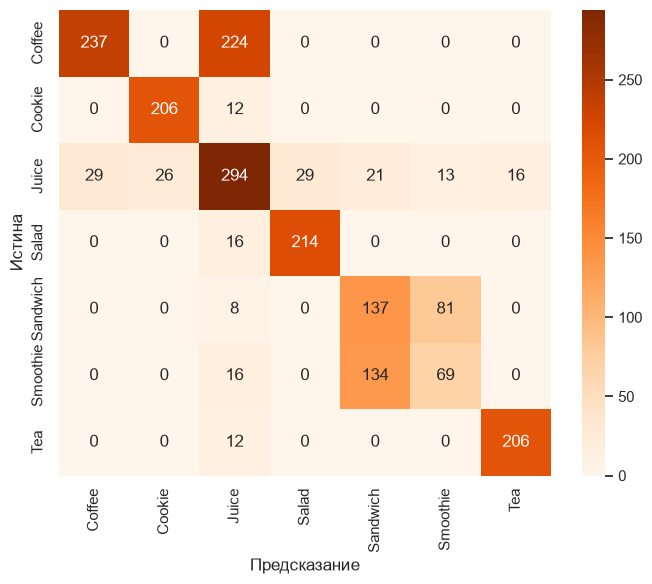

In [23]:
cm_ada = confusion_matrix(y_test, y_pred_ada, labels=ada.classes_)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_ada, annot=True, fmt='d', cmap='Oranges',
            xticklabels=ada.classes_,
            yticklabels=ada.classes_)
plt.ylabel('Истина')
plt.xlabel('Предсказание')
plt.tight_layout()
plt.show()

In [24]:
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE
)
gb.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",45
,"loss loss: {'log_loss', 'exponential'}, default='log_loss'The loss function to be optimized. 'log_loss' refers to binomial andmultinomial deviance, the same as used in logistic regression.It is a good choice for classification with probabilistic outputs.For loss 'exponential', gradient boosting recovers the AdaBoost algorithm.",'log_loss'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.For an example of the effects of this parameter and its interaction with``subsample``, see:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_regularization.py`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (im

In [25]:
y_pred_gb = gb.predict(X_test)
print(accuracy_score(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb, zero_division=0))

0.6835
              precision    recall  f1-score   support

      Coffee       0.76      0.59      0.66       461
      Cookie       0.89      0.94      0.92       218
       Juice       0.51      0.58      0.54       428
       Salad       0.88      0.93      0.90       230
    Sandwich       0.50      0.62      0.56       226
    Smoothie       0.47      0.37      0.41       219
         Tea       0.93      0.94      0.94       218

    accuracy                           0.68      2000
   macro avg       0.70      0.71      0.70      2000
weighted avg       0.69      0.68      0.68      2000



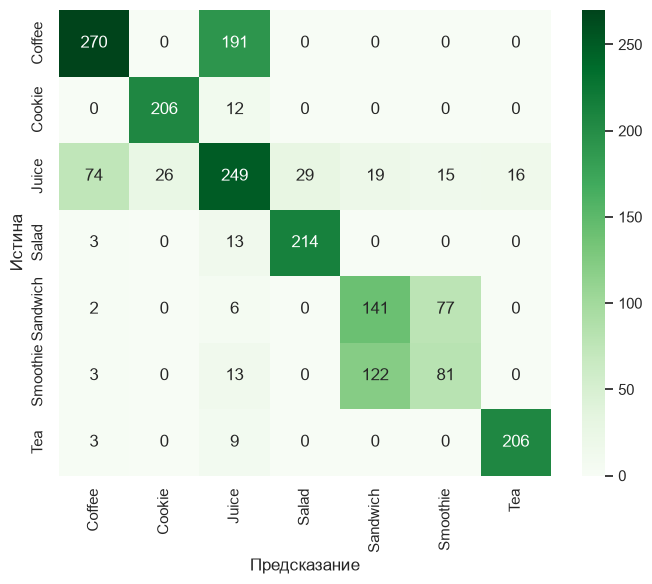

In [26]:
cm_gb = confusion_matrix(y_test, y_pred_gb, labels=gb.classes_)

plt.figure(figsize=(7, 6))
sns.heatmap(cm_gb, annot=True, fmt='d', cmap='Greens',
            xticklabels=gb.classes_,
            yticklabels=gb.classes_)
plt.ylabel('Истина')
plt.xlabel('Предсказание')
plt.tight_layout()
plt.show()

In [27]:
comparison = pd.DataFrame({
    'Model': ['Random Forest', 'AdaBoost', 'Gradient Boosting'],
    'Accuracy': [
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_ada),
        accuracy_score(y_test, y_pred_gb),
    ]
})
comparison

,Model,Accuracy
0,Random Forest,0.6885
1,AdaBoost,0.6815
2,Gradient Boosting,0.6835


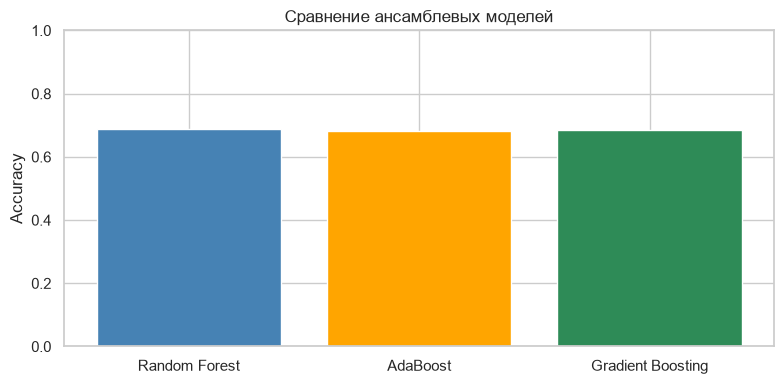

In [28]:
plt.figure(figsize=(8, 4))
plt.bar(comparison['Model'], comparison['Accuracy'],
        color=['steelblue', 'orange', 'seagreen'])
plt.ylabel('Accuracy')
plt.title('Сравнение ансамблевых моделей')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [29]:
classes = sorted(y_clf.unique())
y_test_bin = label_binarize(y_test, classes=classes)
print(classes)
print(y_test_bin.shape)

['Coffee', 'Cookie', 'Juice', 'Salad', 'Sandwich', 'Smoothie', 'Tea']
(2000, 7)


Coffee 0.9321
Cookie 0.9807
Juice 0.7486
Salad 0.9751
Sandwich 0.924
Smoothie 0.917
Tea 0.9764


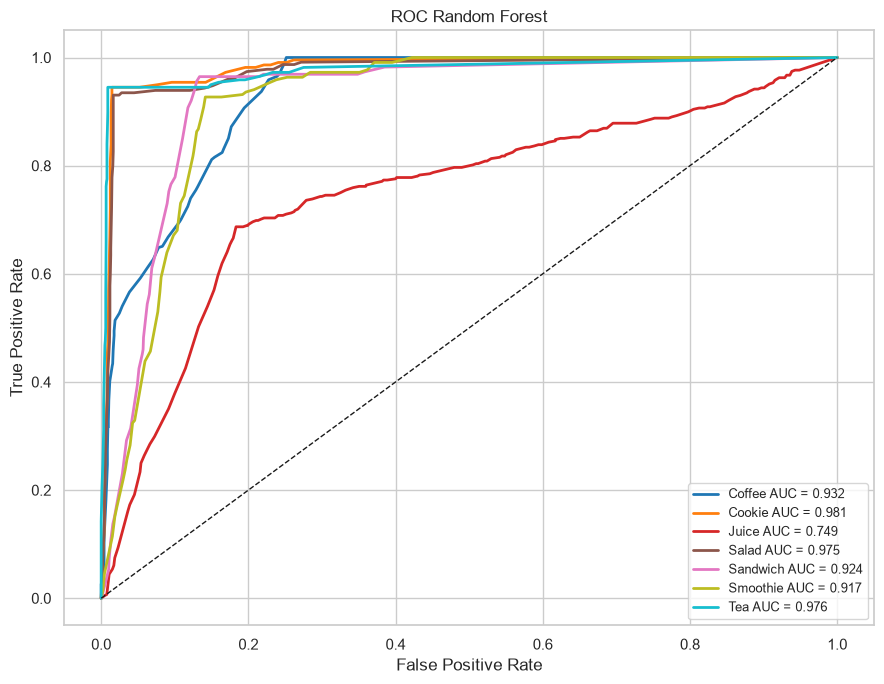

In [30]:
y_score_rf = rf.predict_proba(X_test)
y_score_ada = ada.predict_proba(X_test)
y_score_gb = gb.predict_proba(X_test)
fpr_rf, tpr_rf, auc_rf = {}, {}, {}

for i, cls in enumerate(rf.classes_):
    fpr_rf[cls], tpr_rf[cls], _ = roc_curve(y_test_bin[:, i], y_score_rf[:, i])
    auc_rf[cls] = auc(fpr_rf[cls], tpr_rf[cls])
for cls in classes:
    print(cls, round(auc_rf[cls], 4))
plt.figure(figsize=(9, 7))
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

for cls, color in zip(classes, colors):
    plt.plot(fpr_rf[cls], tpr_rf[cls], color=color, lw=2,
             label=f'{cls} AUC = {auc_rf[cls]:.3f}')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Random Forest')
plt.legend(loc='lower right', fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.show()

Coffee 0.7847
Cookie 0.9797
Juice 0.2332
Salad 0.9628
Sandwich 0.8881
Smoothie 0.9025
Tea 0.9789


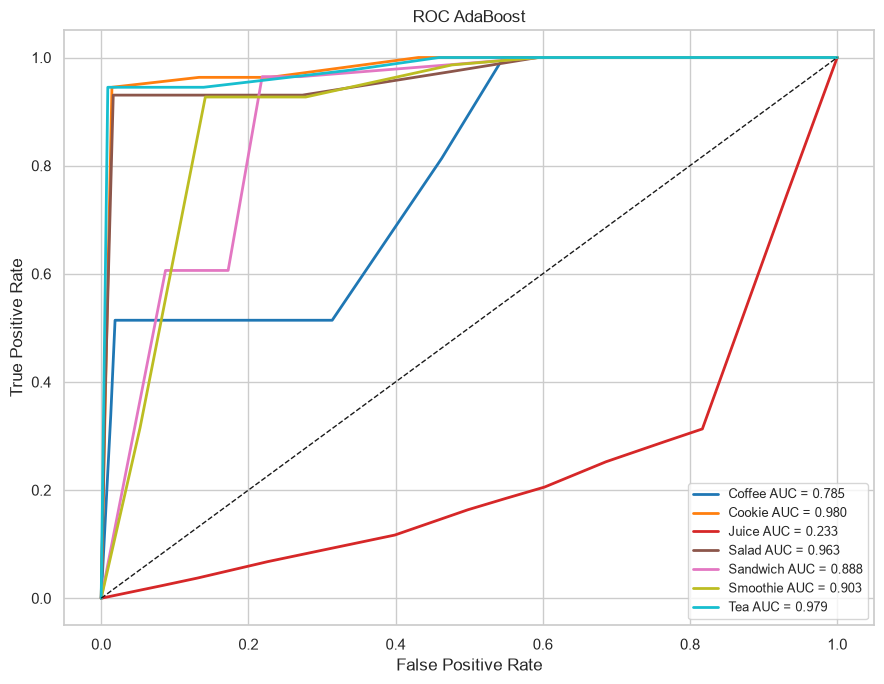

In [31]:
fpr_ada, tpr_ada, auc_ada = {}, {}, {}

for i, cls in enumerate(ada.classes_):
    fpr_ada[cls], tpr_ada[cls], _ = roc_curve(y_test_bin[:, i], y_score_ada[:, i])
    auc_ada[cls] = auc(fpr_ada[cls], tpr_ada[cls])
for cls in classes:
    print(cls, round(auc_ada[cls], 4))
plt.figure(figsize=(9, 7))
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

for cls, color in zip(classes, colors):
    plt.plot(fpr_ada[cls], tpr_ada[cls], color=color, lw=2,
             label=f'{cls} AUC = {auc_ada[cls]:.3f}')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC AdaBoost')
plt.legend(loc='lower right', fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.show()

Coffee 0.9304
Cookie 0.9845
Juice 0.7481
Salad 0.9783
Sandwich 0.9251
Smoothie 0.9111
Tea 0.9835


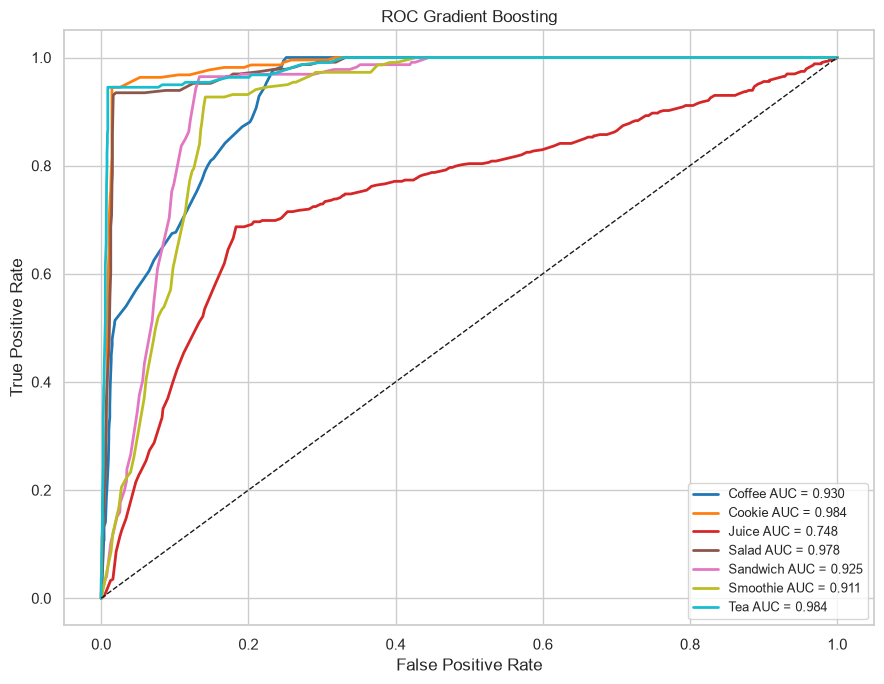

In [32]:
fpr_gb, tpr_gb, auc_gb = {}, {}, {}

for i, cls in enumerate(gb.classes_):
    fpr_gb[cls], tpr_gb[cls], _ = roc_curve(y_test_bin[:, i], y_score_gb[:, i])
    auc_gb[cls] = auc(fpr_gb[cls], tpr_gb[cls])
for cls in classes:
    print(cls, round(auc_gb[cls], 4))
plt.figure(figsize=(9, 7))
colors = plt.cm.tab10(np.linspace(0, 1, len(classes)))

for cls, color in zip(classes, colors):
    plt.plot(fpr_gb[cls], tpr_gb[cls], color=color, lw=2,
             label=f'{cls} AUC = {auc_gb[cls]:.3f}')

plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Gradient Boosting')
plt.legend(loc='lower right', fontsize=9)
plt.grid(True)
plt.tight_layout()
plt.show()

In [33]:
fpr_micro_rf, tpr_micro_rf, _ = roc_curve(y_test_bin.ravel(), y_score_rf.ravel())
fpr_micro_ada, tpr_micro_ada, _ = roc_curve(y_test_bin.ravel(), y_score_ada.ravel())
fpr_micro_gb, tpr_micro_gb, _ = roc_curve(y_test_bin.ravel(), y_score_gb.ravel())

auc_micro_rf = auc(fpr_micro_rf, tpr_micro_rf)
auc_micro_ada = auc(fpr_micro_ada, tpr_micro_ada)
auc_micro_gb = auc(fpr_micro_gb, tpr_micro_gb)

In [34]:
print(round(auc_micro_rf, 4))
print(round(auc_micro_ada, 4))
print(round(auc_micro_gb, 4))

0.9483
0.8836
0.9524


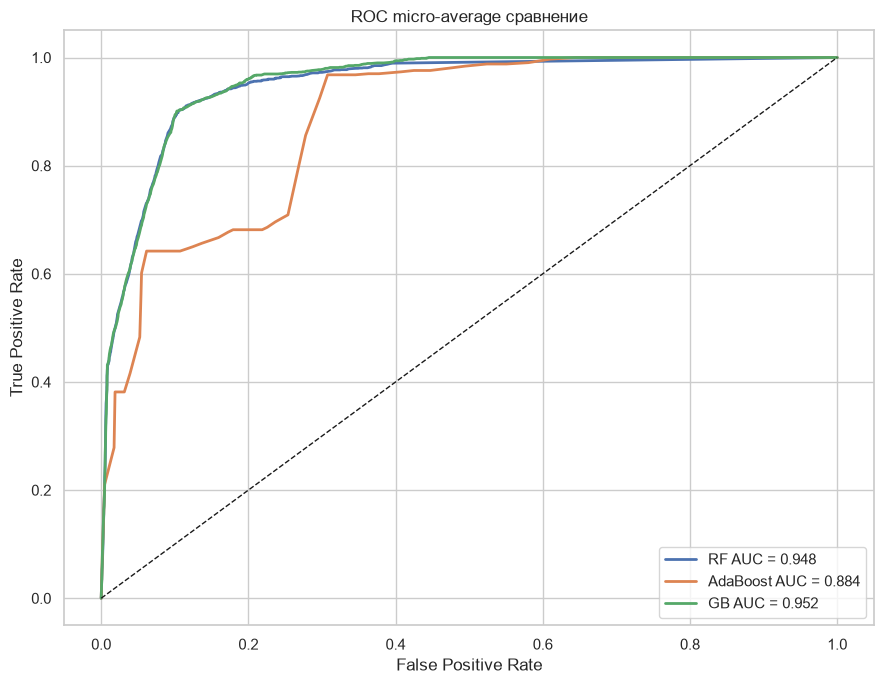

In [35]:
plt.figure(figsize=(9, 7))
plt.plot(fpr_micro_rf, tpr_micro_rf, lw=2,
         label=f'RF AUC = {auc_micro_rf:.3f}')
plt.plot(fpr_micro_ada, tpr_micro_ada, lw=2,
         label=f'AdaBoost AUC = {auc_micro_ada:.3f}')
plt.plot(fpr_micro_gb, tpr_micro_gb, lw=2,
         label=f'GB AUC = {auc_micro_gb:.3f}')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC micro-average сравнение')
plt.legend(loc='lower right')
plt.grid(True)
plt.tight_layout()
plt.show()

In [36]:
comparison.to_csv('lab4_model_comparison.csv', index=False)
with open('lab4_report.txt', 'w', encoding='utf-8') as f:
    f.write("Лабораторная работа 4\n\n")
    f.write(f"OOB Score Random Forest: {rf.oob_score_:.4f}\n")
    f.write(f"OOB Error: {1 - rf.oob_score_:.4f}\n\n")
    f.write(f"Accuracy Random Forest: {accuracy_score(y_test, y_pred_rf):.4f}\n")
    f.write(f"Accuracy AdaBoost: {accuracy_score(y_test, y_pred_ada):.4f}\n")
    f.write(f"Accuracy Gradient Boosting: {accuracy_score(y_test, y_pred_gb):.4f}\n\n")
    f.write(f"Micro AUC Random Forest: {auc_micro_rf:.4f}\n")
    f.write(f"Micro AUC AdaBoost: {auc_micro_ada:.4f}\n")
    f.write(f"Micro AUC Gradient Boosting: {auc_micro_gb:.4f}\n")
import os
for f in sorted(os.listdir()):
    if f.startswith('lab4'):
        print(f)

lab4_model_comparison.csv
lab4_report.txt
